# IBM Telco Customer Churn Supervised Learning
## Take-Home Group Assignment 1 | Group 4

**Members:** Fabio Augusto De Oliveira Dutra; Gumashtha Devangiri Pandukabhaya Punchi Wedikkarage Don; Jose Vidal Asencio Santos; Mehrthur Luís Lemos da Silva.

**Analysis revision:** November 8, 2026.

We compare baseline and optimized Logistic Regression and Decision Tree classifiers using 20 predictors. The objective is churn F1, with churn encoded as 1. The recommended model is a candidate for validation, rather than an approved production system.

**Project workflow:** labeled customer records -> schema and leakage review -> shared stratified 80/20 split -> training-only EDA -> fold-fitted preprocessing -> baseline fitting and training-only tuning -> fixed-model test comparison -> interpretation and operational validation plan.

**Reproduce:** start in this notebook's directory. The loader accepts the repository filename `Dataset_Churn.xlsx` or the supplied local filename `Assignment 1 Dataset.xlsx`. For this saved execution, install `requirements-revised.txt` (Python 3.14.8); the same environment is also recorded in `requirements.txt`. Alternatively install the libraries listed in the import cell, and run all cells in order. The last cell exports the fitted candidate; use the same package versions for inference. Python and package versions are recorded below and in the export.

**Reading guide:** Section 6 contains the required model comparison, followed by supplementary uncertainty, cost, calibration and threshold diagnostics. Section 7 explains the models. Section 8 discusses implications and limitations. For the approximately 10-page report, prioritize the required comparison and main findings; place detailed diagnostics in an appendix.

**Evaluation boundary:** this test split was inspected in earlier project versions. Revised test results and bootstrap intervals are exploratory. They do not provide an untouched final evaluation. Diagnostic analyses below do not change the chosen hyperparameters, model-selection objective, or default prediction threshold.


## 1. Problem definition — 10 marks

**Domain:** telecommunications customer retention.  
**Business problem:** help the retention team identify customers likely to leave and prioritize contact.  
**Prediction objective:** binary classification of recorded churn outcomes.  
**Target:** `Churn Value`, with churn = 1 and no churn = 0.  
**Predictors:** ZIP Code; Gender; Senior Citizen; Partner; Dependents; Tenure Months; Phone Service; Multiple Lines; Internet Service; Online Security; Online Backup; Device Protection; Tech Support; Streaming TV; Streaming Movies; Contract; Paperless Billing; Payment Method; Monthly Charges; Total Charges.

Historical labeled examples make supervised learning suitable. The intended operational use would score active customers before a retention decision. The file does not establish a future prediction horizon or verify the timing of every input, so production use requires a data-availability review.

A false negative misses a churner; a false positive may waste an offer or contact. Financial costs are unknown, so churn F1 balances precision and recall. Predictive associations do not prove that a retention action prevents churn. Dataset source: [1].

In [1]:
# Install dependencies in the notebook environment if necessary:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score,
)
import sklearn

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
import platform
import scipy
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| SciPy:", scipy.__version__)


pandas: 3.0.6 | scikit-learn: 1.9.1
Python: 3.14.8 | NumPy: 2.5.3 | SciPy: 1.18.1


## 2. Load and inspect the dataset

Source: [IBM Telco Customer Churn Dataset on Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset).

Set the exact downloaded filename. The loader supports CSV and Excel; inspect the sheet names if the workbook contains multiple sheets. Column names and label values are validated rather than assuming a particular dataset variant.

In [2]:
# Support both the repository and the supplied assignment copy.
data_candidates = [Path("Dataset_Churn.xlsx"), Path("Assignment 1 Dataset.xlsx")]
DATA_PATH = next((p for p in data_candidates if p.is_file()), data_candidates[0])
EXCEL_SHEET = 0

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Download the dataset, "
        "place it beside this notebook, and update DATA_PATH."
    )
if DATA_PATH.suffix.lower() == ".csv":
    raw = pd.read_csv(DATA_PATH)
elif DATA_PATH.suffix.lower() in {".xlsx", ".xls"}:
    raw = pd.read_excel(DATA_PATH, sheet_name=EXCEL_SHEET)
else:
    raise ValueError("Use a CSV or Excel file; extract downloaded ZIP archives first.")
raw.columns = raw.columns.str.strip()
if raw.columns.duplicated().any():
    raise ValueError("Duplicate column names found; inspect the source file.")
print("Raw dimensions:", raw.shape)
display(raw.head())
raw.info()
display(raw.describe(include="all").T)
display(raw.isna().sum().sort_values(ascending=False).to_frame("Missing"))
print("Exact duplicate rows:", raw.duplicated().sum())


Raw dimensions: (7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3668-QPYBK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"33.964131, -118.272783",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing
Churn Reason,5174
Online Security,0
CLTV,0
Churn Score,0
Churn Value,0
Churn Label,0
Total Charges,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0


### Target, schema, and leakage review

`Churn Value` is the target. `Churn Label` gives the same outcome in text. CustomerID, Count, Churn Label, Churn Score and Churn Reason are excluded. CLTV is excluded because its calculation and availability before churn were not confirmed; this does not prove that CLTV contains leakage.

Country and State are constant in this file. City, Lat Long, Latitude and Longitude are removed to avoid retaining several encodings of location. ZIP Code is kept as the single geographic field and converted to a five-character string before one-hot encoding. This is a schema decision rather than a feature ranking based on test results. ZIP Code still has many categories, which is a limitation to validate.

Whitespace-only entries become missing values. Billing fields are converted to numbers. Exact duplicates are checked before splitting; repeated customer IDs trigger an error and further investigation. The remaining fields represent plausible customer and account inputs, but their production-time availability is an assumption to verify. Pipeline practice follows [2].

In [3]:
def column_key(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

TARGET_COLUMN = "Churn Value"  # Set explicitly if automatic detection is ambiguous.
target_keys = {"churn", "churnlabel", "churnvalue"}
candidates = [c for c in raw.columns if column_key(c) in target_keys]
if TARGET_COLUMN is None:
    if len(candidates) != 1:
        raise ValueError(f"Set TARGET_COLUMN explicitly. Candidate target fields: {candidates}")
    TARGET_COLUMN = candidates[0]
if TARGET_COLUMN not in raw.columns:
    raise ValueError(f"Target not found: {TARGET_COLUMN}")

# Extend after reading the dataset dictionary and defining the prediction time.
# Keep ZIP Code as the single geographic representation. Remove constant
# fields and repeated location encodings based on schema, not test scores.
EXTRA_EXCLUDE = ["CLTV", "Country", "State", "City", "Lat Long", "Latitude", "Longitude"]
excluded_keys = {
    "customerid", "customerstatus", "churn", "churnlabel", "churnvalue",
    "churnscore", "churncategory", "churnreason", "count",
}
excluded = [c for c in raw.columns
            if c != TARGET_COLUMN and (column_key(c) in excluded_keys or c in EXTRA_EXCLUDE)]

clean = raw.copy()
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    clean[col] = clean[col].map(lambda value: value.strip() if isinstance(value, str) else value)
clean = clean.replace(r"^\s*$", np.nan, regex=True)
for col in clean.columns:
    if column_key(col) in {"totalcharges", "monthlycharges", "monthlycharge"}:
        clean[col] = pd.to_numeric(clean[col], errors="raise")

before = len(clean)
clean = clean.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(clean))
if clean[TARGET_COLUMN].isna().any():
    raise ValueError("Missing target labels found. Investigate before proceeding.")
label_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}
y = clean[TARGET_COLUMN].astype(str).str.strip().str.lower().map(label_map)
if y.isna().any() or y.nunique() != 2:
    raise ValueError("Expected two target classes encoded as Yes/No or 1/0. Inspect target values.")
y = y.astype(int).rename("Churn")
X = clean.drop(columns=[TARGET_COLUMN] + excluded)
# ZIP codes identify areas; numeric distances between codes have no meaning.
for col in X.columns:
    if column_key(col) == "zipcode":
        codes = pd.to_numeric(X[col], errors="raise")
        if ((codes.dropna() % 1) != 0).any():
            raise ValueError("ZIP Code must contain integer codes or missing values.")
        X[col] = codes.map(lambda value: f"{int(value):05d}" if pd.notna(value) else np.nan)
if X.empty:
    raise ValueError("No predictors remain.")
print("Target:", TARGET_COLUMN)
print("Excluded columns:", excluded)
display(pd.DataFrame({"dtype": X.dtypes, "unique": X.nunique(), "missing": X.isna().sum()}))

id_cols = [c for c in clean.columns if column_key(c) == "customerid"]
for col in id_cols:
    if clean[col].duplicated().any():
        raise ValueError("Repeated customer IDs found. Investigate and use a customer-level split if needed.")

Exact duplicate rows removed: 0
Target: Churn Value
Excluded columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']


,dtype,unique,missing
Zip Code,str,1652,0
Gender,str,2,0
Senior Citizen,str,2,0
Partner,str,2,0
Dependents,str,2,0
Tenure Months,int64,73,0
Phone Service,str,2,0
Multiple Lines,str,3,0
Internet Service,str,3,0
Online Security,str,3,0


### Protect the final test set

Use the same stratified 80/20 split for all four models. Detailed exploratory analysis below uses training data only. Learned preprocessing is fitted separately inside each cross-validation training fold.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training dimensions:", X_train.shape)
print("Test dimensions:", X_test.shape)
eda = X_train.copy()
eda["Churn"] = y_train
class_summary = y_train.value_counts().sort_index().to_frame("Count")
class_summary["Proportion"] = y_train.value_counts(normalize=True).sort_index()
display(class_summary)
display(X_train.describe(include="all").T)
display(X_train.isna().sum().sort_values(ascending=False).to_frame("Training missing"))

Training dimensions: (5634, 20)
Test dimensions: (1409, 20)


,Count,Proportion
Churn,,
0,4139,0.734647
1,1495,0.265353


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Zip Code,5634,1650,91302,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,5634,2,Male,2833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Senior Citizen,5634,2,No,4714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,5634,2,No,2905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,5634,2,No,4333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure Months,5634.0,NaN,NaN,NaN,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0
Phone Service,5634,2,Yes,5075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Multiple Lines,5634,3,No,2685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet Service,5634,3,Fiber optic,2483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online Security,5634,3,No,2797,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Training missing
Total Charges,8
Gender,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0
Contract,0
Streaming Movies,0
Streaming TV,0
Tech Support,0
Device Protection,0


## 3. Exploratory data analysis — 15 marks

The figures examine class distribution and associations with churn. They use training observations only. Review the plots and explain their implications; class balance alone does not determine the best metric.

Tenure for missing Total Charges:


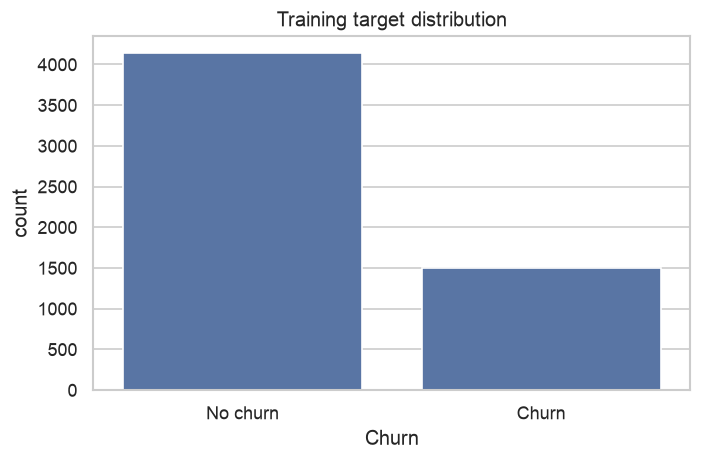

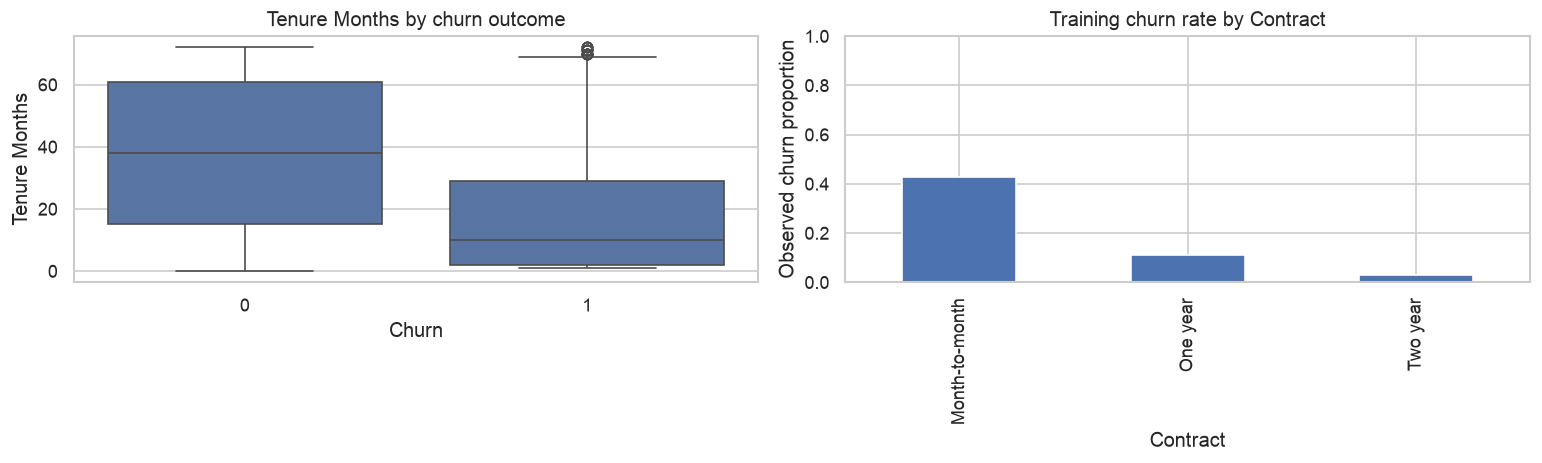

,Churn rate,Customers
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


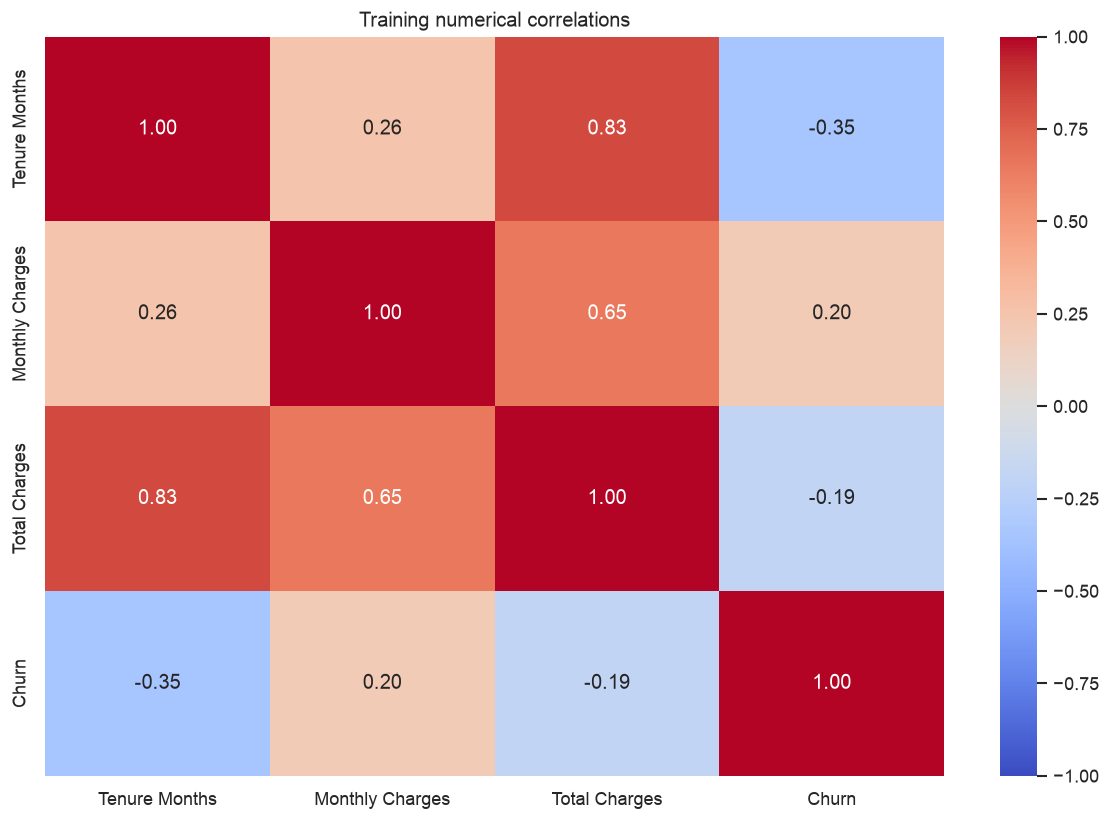

,Correlation with churn
Tenure Months,-0.345593
Total Charges,-0.194814
Monthly Charges,0.198040


,Tenure Months,Monthly Charges,Total Charges
Churn,,,
No churn,38.0,64.40,1691.9
Churn,10.0,79.95,740.3


,Outside 1.5 IQR fences
Tenure Months,0
Monthly Charges,0
Total Charges,0


Tenure Months
0    11
Name: count, dtype: int64

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=eda, x="Churn", ax=ax)
ax.set_xticks([0, 1], ["No churn", "Churn"])
ax.set_title("Training target distribution")
plt.tight_layout()
plt.show()

numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = [c for c in X_train.columns if c not in numeric_columns]
# Prefer interpretable fields, with fallbacks for other dataset variants.
by_key = {column_key(c): c for c in X_train.columns}
num_plot = next((by_key[k] for k in ["tenure", "tenuremonths", "tenureinmonths", "monthlycharges", "monthlycharge"]
                 if k in by_key and by_key[k] in numeric_columns), None)
if num_plot is None and numeric_columns:
    num_plot = numeric_columns[0]
cat_plot = next((by_key[k] for k in ["contract", "internetservice", "paymentmethod"]
                 if k in by_key and by_key[k] in categorical_columns), None)
if cat_plot is None:
    cat_plot = next((c for c in categorical_columns if X_train[c].nunique() <= 15), None)
if num_plot is None or cat_plot is None:
    raise ValueError("Select suitable numerical and categorical fields for the required EDA plots.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=eda, x="Churn", y=num_plot, ax=axes[0])
axes[0].set_title(f"{num_plot} by churn outcome")
rates = eda.groupby(cat_plot, observed=True)["Churn"].agg(["mean", "size"])
rates["mean"].plot.bar(ax=axes[1])
axes[1].set_ylabel("Observed churn proportion")
axes[1].set_ylim(0, 1)
axes[1].set_title(f"Training churn rate by {cat_plot}")
plt.tight_layout()
plt.show()
display(rates.rename(columns={"mean": "Churn rate", "size": "Customers"}))

if numeric_columns:
    corr = eda[numeric_columns + ["Churn"]].corr()
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title("Training numerical correlations")
    plt.tight_layout()
    plt.show()
# Numerical evidence for the written EDA, using training data only.
display(corr["Churn"].drop("Churn").sort_values().to_frame("Correlation with churn"))
eda_by_churn = eda.groupby("Churn")[numeric_columns].median()
display(eda_by_churn.rename(index={0: "No churn", 1: "Churn"}))
q1 = X_train[numeric_columns].quantile(0.25)
q3 = X_train[numeric_columns].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((X_train[numeric_columns] < q1 - 1.5 * iqr) |
                  (X_train[numeric_columns] > q3 + 1.5 * iqr)).sum()
display(outlier_counts.to_frame("Outside 1.5 IQR fences"))
print("Tenure for missing Total Charges:")
display(clean.loc[clean["Total Charges"].isna(), "Tenure Months"].value_counts())


### EDA interpretation

**Dimensions and types.** The original file has 7,043 customers and 33 columns. We exclude 12 fields and use Churn Value as the target, leaving 20 predictors: 3 numerical and 17 categorical. The training set has 5,634 customers and the test set has 1,409. ZIP Code is categorical, and Total Charges was converted from text to numeric.

**Missing values.** Total Charges has 11 missing values in the full file, including 8 in training. All 11 affected records have zero tenure. This suggests that these customers may not yet have accumulated charges, although the file does not confirm the cause. We use the training-fold median rather than assume a true charge of zero. Churn Reason is missing for 5,174 customers, matching the number of non-churners; it is excluded because it describes an outcome. No exact duplicate records were found.

**Class balance.** Training contains 4,139 non-churners (73.46%) and 1,495 churners (26.54%). A classifier that always predicts no churn would have 73.46% training accuracy but zero churn recall. This explains why accuracy alone is insufficient.

**Relationships supported by the figures and tables:**

1. Churners have median tenure of 10 months, compared with 38 months for non-churners. The tenure–churn correlation is −0.3456. Shorter customer relationships are associated with churn in this sample.
2. Month-to-month contracts have 42.75% churn (3,102 training customers), compared with 11.08% for one-year contracts (1,173) and 2.87% for two-year contracts (1,359). Contract type may be useful for classification.
3. Churners have median monthly charges of 79.95, compared with 64.40 for non-churners. Monthly charges have correlation 0.1980 with churn. Higher monthly charges are associated with more churn, but the relationship is modest.
4. Median total charges are lower for churners (740.30) than non-churners (1,691.90); correlation with churn is −0.1948. Total charges reflect both billing and duration, so the result should not be interpreted as a causal effect of paying more.

**Outliers.** None of the three numerical predictors falls outside its training-data 1.5-IQR fences. This rule does not prove the data is error-free. Total Charges is right-skewed: its mean is 2,302.60 and median is 1,398.13. High values may be valid for longer-term customers, so no numerical rows were removed.

**Implications.** Tenure, contract and charges deserve attention in interpretation. The evidence shows associations, not causes. All detailed EDA and numerical summaries above use training data; basic file-quality checks describe the full source.

## 4. Data preprocessing — 15 marks

The same transformations and observations are used for all four models.

| Decision | Implementation and reason |
| --- | --- |
| Missing numeric values | Median fitted on each training fold; retains customers and is less sensitive to skew than the mean. |
| Missing categories | Most-frequent category fitted on each training fold. |
| ZIP Code | Five-character string and one-hot encoding; numeric distance between postal codes has no business meaning. |
| Other categories | One-hot encoding with unseen categories ignored; avoids imposing an artificial order. |
| Numerical scale | StandardScaler for the three numerical inputs; supports Logistic Regression and keeps preprocessing common. Trees do not require scaling. |
| Constant fields | Remove Country, State and Count; they do not vary in this file. |
| Repeated location fields | Remove City, Lat Long, Latitude and Longitude; retain ZIP Code as one geographic representation. |
| Identifier and outcomes | Remove CustomerID, Churn Label, Churn Score and Churn Reason. |
| CLTV | Exclude because calculation and availability before churn are unconfirmed; this is precautionary, not proof of leakage. |
| Duplicates | Check before splitting; none were found, so no rows were removed. |
| Split | Stratified 80/20 split with random_state=42; preserves class proportions and keeps the comparison consistent. |

All learned transformations are inside Pipeline and ColumnTransformer so each CV fold learns its own imputation, encoding and scaling [2]. No resampling is performed; balanced class weights are considered during Logistic Regression tuning. The shared preprocessing satisfies the assignment's fair-comparison requirement.

In [6]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])

def make_model(estimator):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", estimator)])

all_missing = X_train.columns[X_train.isna().all()].tolist()
if all_missing:
    raise ValueError(f"Entirely missing training columns require a decision: {all_missing}")

## 5. Model development and optimization — 25 marks

**Logistic Regression:** a regularized linear classification reference with coefficients that can be inspected [3].  
**Decision Tree:** learns nonlinear rules and interactions, but an unrestricted tree may overfit [4].

Baseline means the initial untuned version of each required algorithm. Both use random_state=42 where applicable. Logistic Regression uses max_iter=3000; the tree baseline is unrestricted.

**Selection metric:** F1 for churn balances precision and recall when financial error costs are not known. We do not change this objective after looking at the revised test. Five shuffled stratified folds are shared across candidates. GridSearchCV evaluates the grid on training data and refits the best candidate on the full training set [5]. All preprocessing is inside the searched pipeline [2]. The default class decision is used; no threshold is tuned on the test set.

In [7]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
SELECTION_METRIC = "f1"
if y_train.value_counts().min() < CV.n_splits:
    raise ValueError("Not enough minority-class observations for five-fold stratified CV.")

baseline_models = {
    "Logistic Regression (Baseline)": make_model(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    "Decision Tree (Baseline)": make_model(
        DecisionTreeClassifier(random_state=RANDOM_STATE)),
}
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {"Model": name}
    for metric in SCORING:
        row[f"CV {metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"CV {metric} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)
    model.fit(X_train, y_train)
display(pd.DataFrame(cv_rows).set_index("Model").round(4))

,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression (Baseline),0.8072,0.0095,0.6592,0.0220,0.5672,0.0325,0.6093,0.023,0.8488,0.0132
Decision Tree (Baseline),0.7657,0.0118,0.5658,0.0275,0.5084,0.0389,0.5347,0.027,0.6835,0.0175


In [8]:
search_specs = {
    "Optimized Logistic Regression": (
        make_model(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1.0, 10.0],
         "model__class_weight": [None, "balanced"]},
    ),
    "Optimized Decision Tree": (
        make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {"model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 5, 15],
         "model__min_samples_split": [2, 10],
         "model__criterion": ["gini", "entropy"]},
    ),
}
searches = {}
for name, (pipeline, param_grid) in search_specs.items():
    search = GridSearchCV(
        pipeline, param_grid, cv=CV, scoring=SCORING,
        refit=SELECTION_METRIC, n_jobs=-1, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(name)
    print("Best parameters:", search.best_params_)
    print("Best cross-validation F1:", round(search.best_score_, 4))
    results = pd.DataFrame(search.cv_results_)
    display(results[["params", "mean_test_f1", "std_test_f1", "mean_test_recall",
                     "mean_test_precision"]].sort_values("mean_test_f1", ascending=False).head())

models = {**baseline_models, **{name: search.best_estimator_ for name, search in searches.items()}}
selection_rows = [{"Model": row["Model"], "CV F1": row["CV f1 mean"]} for row in cv_rows]
selection_rows += [{"Model": name, "CV F1": search.best_score_} for name, search in searches.items()]
selection_table = pd.DataFrame(selection_rows).set_index("Model").sort_values("CV F1", ascending=False)
recommended_name = selection_table.index[0]
display(selection_table)
print("Model selected using training CV only:", recommended_name)

optimization_summary = [{"Model": row["Model"], "Mean CV F1": row["CV f1 mean"],
    "Fold SD": row["CV f1 std"], "Settings": "Initial untuned configuration"} for row in cv_rows]
for name, search in searches.items():
    optimization_summary.append({"Model": name, "Mean CV F1": search.best_score_,
        "Fold SD": search.cv_results_["std_test_f1"][search.best_index_],
        "Settings": str(search.best_params_)})
display(pd.DataFrame(optimization_summary).set_index("Model").round(4))


Optimized Logistic Regression
Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.6432
Optimized Decision Tree
Best parameters: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 15, 'model__min_samples_split': 2}
Best cross-validation F1: 0.6128
Model selected using training CV only: Optimized Logistic Regression


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.643161,0.022411,0.804682,0.535986
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.637458,0.021812,0.793311,0.533076
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.629339,0.024537,0.765886,0.534316
2,"{'model__C': 0.1, 'model__class_weight': None}",0.616030,0.032839,0.571906,0.668946
4,"{'model__C': 1.0, 'model__class_weight': None}",0.609298,0.022970,0.567224,0.659203


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
35,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
34,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
33,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
32,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
31,"{'model__criterion': 'entropy', 'model__max_de...",0.611231,0.028001,0.614716,0.614176


,CV F1
Model,
Optimized Logistic Regression,0.643161
Optimized Decision Tree,0.612828
Logistic Regression (Baseline),0.609298
Decision Tree (Baseline),0.534724


,Mean CV F1,Fold SD,Settings
Model,,,
Logistic Regression (Baseline),0.6093,0.0230,Initial untuned configuration
Decision Tree (Baseline),0.5347,0.0270,Initial untuned configuration
Optimized Logistic Regression,0.6432,0.0224,"{'model__C': 0.1, 'model__class_weight': 'bala..."
Optimized Decision Tree,0.6128,0.0290,"{'model__criterion': 'entropy', 'model__max_de..."


### Optimization interpretation

The next table is generated from this execution, so package-dependent differences are not hidden behind stale values. Logistic Regression tests 8 combinations: C in {0.01, 0.1, 1, 10}, with or without balanced class weights. Smaller C increases regularization. The tree tests 48 combinations: depth in {3, 5, 8, None}, leaf minimum in {1, 5, 15}, split minimum in {2, 10}, and Gini or entropy.

CV churn F1 selects the configuration and candidate model. Fold standard deviation describes variability; it is not a confidence interval. The best grid score is subject to selection optimism. Subsequent diagnostics do not provide independent validation or justify retuning on the test set.

## 6. Revised test evaluation and comparison — 20 marks

Evaluate the four fixed models on the same 1,409 test customers. The displayed test has already been examined in earlier project versions; it is a revised comparison, not a new untouched validation. Hyperparameters and the model recommendation are selected using training-only CV. Do not use these test scores to restart tuning. New independent data is needed for the next final validation.


Logistic Regression (Baseline)
              precision    recall  f1-score   support

    No churn     0.8487    0.8831    0.8655      1035
       Churn     0.6355    0.5642    0.5977       374

    accuracy                         0.7984      1409
   macro avg     0.7421    0.7236    0.7316      1409
weighted avg     0.7921    0.7984    0.7944      1409


Decision Tree (Baseline)
              precision    recall  f1-score   support

    No churn     0.8413    0.8551    0.8481      1035
       Churn     0.5798    0.5535    0.5663       374

    accuracy                         0.7750      1409
   macro avg     0.7105    0.7043    0.7072      1409
weighted avg     0.7719    0.7750    0.7733      1409


Optimized Logistic Regression
              precision    recall  f1-score   support

    No churn     0.8972    0.7420    0.8123      1035
       Churn     0.5172    0.7647    0.6170       374

    accuracy                         0.7480      1409
   macro avg     0.7072    0.7534    0.

,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,Comments
Model,,,,,,
Logistic Regression (Baseline),0.8608,0.7984,0.6355,0.5642,0.5977,Highest test accuracy; lower churn recall than...
Decision Tree (Baseline),1.0000,0.7750,0.5798,0.5535,0.5663,Perfect training accuracy; largest accuracy gap
Optimized Logistic Regression,0.7728,0.7480,0.5172,0.7647,0.6170,Highest churn F1 and recall; most false alerts
Optimized Decision Tree,0.8032,0.7913,0.6081,0.6016,0.6048,Smallest accuracy gap; fewer false alerts than...


,ROC-AUC,Average Precision,Accuracy Gap,TP,FN,FP,TN,Flagged Customers
Model,,,,,,,,
Logistic Regression (Baseline),0.8439,0.6424,0.0624,211,163,121,914,332
Decision Tree (Baseline),0.7043,0.4394,0.2250,207,167,150,885,357
Optimized Logistic Regression,0.8487,0.6478,0.0248,286,88,267,768,553
Optimized Decision Tree,0.8354,0.6155,0.0118,225,149,145,890,370


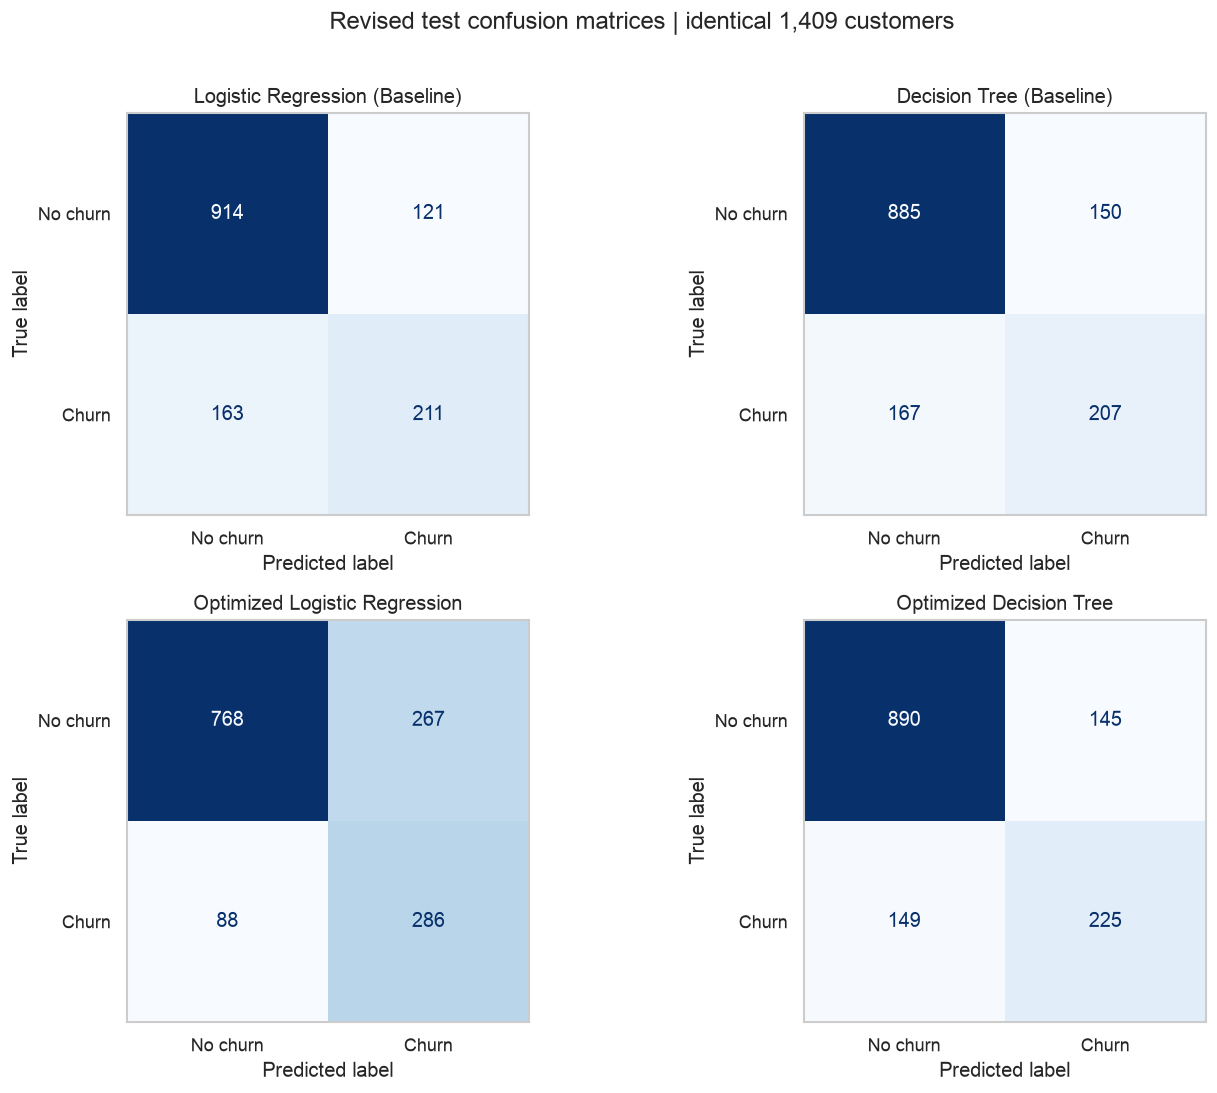

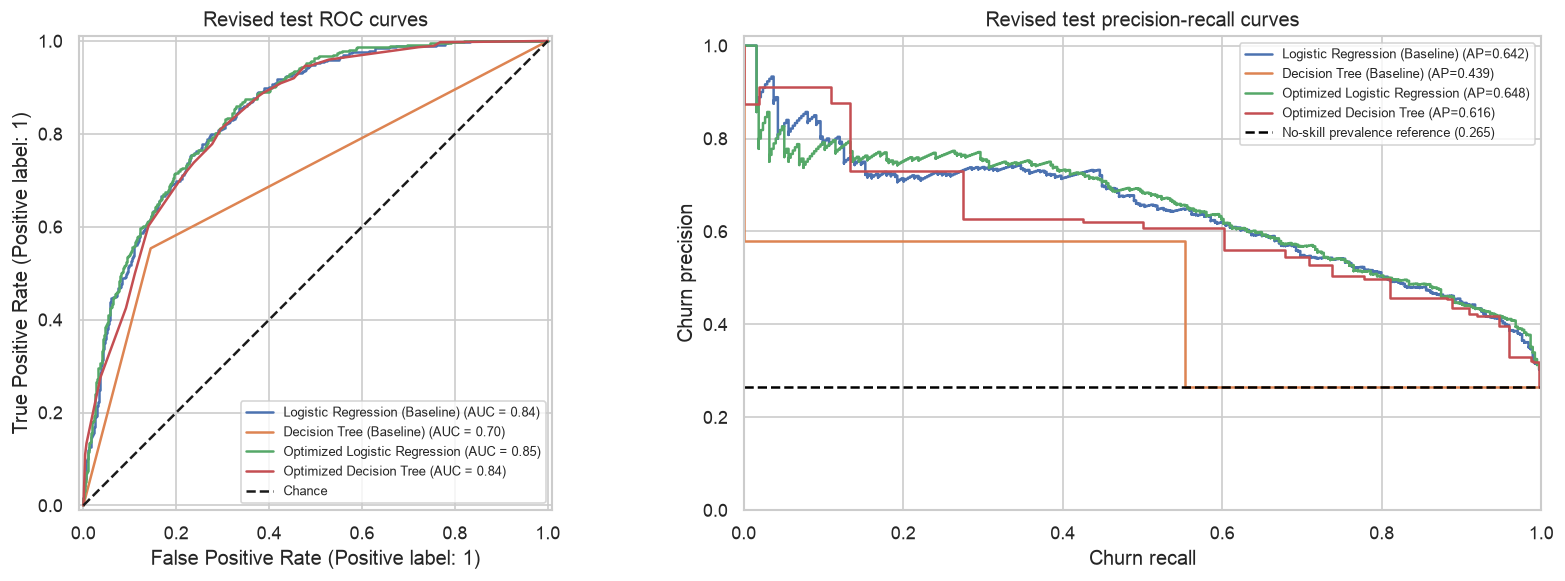

,Accuracy change (percentage points),Precision change (percentage points),Recall change (percentage points),F1 change (absolute)
Algorithm,,,,
Logistic Regression,-5.0390,-11.8363,20.0535,0.0193
Decision Tree,1.6324,2.8276,4.8128,0.0385


In [9]:
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix

# Every metric uses the same customers and the same fitted pipelines.
# Positive-class metrics explicitly use Churn = 1; predict() retains the default decision.
evaluation_rows, test_predictions, test_probabilities = [], {}, {}
diagnostic_comments = {
    "Logistic Regression (Baseline)": "Highest test accuracy; lower churn recall than optimized LR",
    "Decision Tree (Baseline)": "Perfect training accuracy; largest accuracy gap",
    "Optimized Logistic Regression": "Highest churn F1 and recall; most false alerts",
    "Optimized Decision Tree": "Smallest accuracy gap; fewer false alerts than optimized LR",
}
for name, model in models.items():
    train_pred = model.predict(X_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    test_predictions[name], test_probabilities[name] = pred, prob
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    evaluation_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Average Precision": average_precision_score(y_test, prob),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "Flagged Customers": int(tp + fp),
    })
    print("\n" + name)
    print(classification_report(y_test, pred, labels=[0, 1],
          target_names=["No churn", "Churn"], digits=4, zero_division=0))
comparison = pd.DataFrame(evaluation_rows).set_index("Model")
comparison["Accuracy Gap"] = comparison["Train Accuracy"] - comparison["Test Accuracy"]
comparison["Comments"] = pd.Series(diagnostic_comments)
display(comparison[["Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1-score", "Comments"]].round(4))
print("Precision, recall and F1 refer to Churn = 1. Accuracy includes both classes.")
print("Train accuracy is resubstitution accuracy, not out-of-fold accuracy.")
display(comparison[["ROC-AUC", "Average Precision", "Accuracy Gap", "TP", "FN", "FP", "TN", "Flagged Customers"]].round(4))

# A non-learning reference contextualizes accuracy under class imbalance.
majority_pred = np.full(len(y_test), y_train.mode().iloc[0], dtype=int)
print(f"Always-no-churn reference: accuracy={accuracy_score(y_test, majority_pred):.4f}, "
      f"churn recall={recall_score(y_test, majority_pred, zero_division=0):.4f}, "
      f"churn F1={f1_score(y_test, majority_pred, zero_division=0):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=["No churn", "Churn"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
fig.suptitle("Revised test confusion matrices | identical 1,409 customers", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    pr_precision, pr_recall, _ = precision_recall_curve(y_test, prob)
    axes[1].step(pr_recall, pr_precision, where="post",
                 label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("Revised test ROC curves")
axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="black", linestyle="--",
               label=f"No-skill prevalence reference ({y_test.mean():.3f})")
axes[1].set(xlabel="Churn recall", ylabel="Churn precision", xlim=(0, 1), ylim=(0, 1.02),
            title="Revised test precision-recall curves")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

change_rows = []
for algorithm, baseline, optimized in [
    ("Logistic Regression", "Logistic Regression (Baseline)", "Optimized Logistic Regression"),
    ("Decision Tree", "Decision Tree (Baseline)", "Optimized Decision Tree"),
]:
    delta = comparison.loc[optimized]  # Numeric columns selected individually below.
    change_rows.append({"Algorithm": algorithm,
        "Accuracy change (percentage points)": 100 * (delta["Test Accuracy"] - comparison.loc[baseline, "Test Accuracy"]),
        "Precision change (percentage points)": 100 * (delta["Precision"] - comparison.loc[baseline, "Precision"]),
        "Recall change (percentage points)": 100 * (delta["Recall"] - comparison.loc[baseline, "Recall"]),
        "F1 change (absolute)": delta["F1-score"] - comparison.loc[baseline, "F1-score"],
    })
display(pd.DataFrame(change_rows).set_index("Algorithm").round(4))


### Comparison discussion

**Best model depends on the objective.** Optimized Logistic Regression is selected using the highest training CV churn F1. The revised test table supports comparison under that same objective. Baseline Logistic Regression has the highest test accuracy in the original experiment. Accuracy, ranking quality and churn detection measure different aspects of performance; they need not select the same model.

**Generalization and overfitting.** The unrestricted tree's perfect training accuracy and much lower test accuracy indicate overfitting. Restricting complexity substantially reduces that gap. A small gap alone does not establish the best model: a consistently weak classifier can also have a small gap. Assess test F1, recall, precision and validation evidence together. Training accuracy here is evaluated on the fitting observations, whereas CV scores use held-out folds.

**Did optimization help?** The change table reports absolute F1 changes and percentage-point changes for the other decision metrics. The LR search changes both regularization and class weighting; the tree search changes complexity and impurity settings. Gains cannot be attributed to one setting without controlled comparisons. F1 tuning can improve churn detection while reducing overall accuracy.

**Errors and capacity.** Use the TP/FN/FP/TN counts and flagged-customer totals to connect metrics to retention workload. Higher recall can require contacting many more customers. False alerts are wasted contacts only under a simplified business assumption; observed churn labels do not tell us which customers would respond to an offer.

**Recommendation.** Retain the CV-selected optimized Logistic Regression as the candidate under the predeclared F1 objective. The paired bootstrap quantifies conditional sampling uncertainty, and the cost scenarios show why a business preference can change. Neither makes the recommendation statistically proven, profitable or production-ready. The alternative optimized tree remains a credible candidate when contact capacity or false-alert cost dominates.


### Uncertainty and business sensitivity

A small score difference does not establish a reliable winner. We use a **paired, class-stratified bootstrap**: resample churners and non-churners separately, retain the observed class counts, and evaluate every fixed model on the same sampled customers. This estimates conditional test-sample variation at the observed prevalence. It does not capture retraining variation, hyperparameter selection, test reuse, customer dependence, or population change.

The simplified error-cost scenario uses `cost = FN * missed_churn_cost + FP * false_alert_cost`. It is a sensitivity analysis, not campaign profit: it omits contact costs for true positives, intervention effectiveness, customer value differences, and capacity constraints. We do not choose a new threshold or model from these test scenarios.


In [10]:
# NumPy counting keeps the 2,000 paired bootstrap repetitions fast and transparent.
rng = np.random.default_rng(RANDOM_STATE)
y_array = y_test.to_numpy()
groups = [np.flatnonzero(y_array == label) for label in (0, 1)]
names = list(test_predictions)
bootstrap_f1 = {name: np.empty(2000) for name in names}
for b in range(2000):
    idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
    truth = y_array[idx]
    for name in names:
        pred = np.asarray(test_predictions[name])[idx]
        tp = np.count_nonzero((truth == 1) & (pred == 1))
        fp = np.count_nonzero((truth == 0) & (pred == 1))
        fn = np.count_nonzero((truth == 1) & (pred == 0))
        bootstrap_f1[name][b] = 2 * tp / (2 * tp + fp + fn)
intervals = pd.DataFrame([
    {"Model": name, "Observed F1": comparison.loc[name, "F1-score"],
     "Conditional 95% lower": np.quantile(values, .025),
     "Conditional 95% upper": np.quantile(values, .975)}
    for name, values in bootstrap_f1.items()
]).set_index("Model")
display(intervals.round(4))
f1_differences = bootstrap_f1["Optimized Logistic Regression"] - bootstrap_f1["Optimized Decision Tree"]
paired_interval = np.quantile(f1_differences, [.025, .975])
observed_difference = comparison.loc["Optimized Logistic Regression", "F1-score"] - comparison.loc["Optimized Decision Tree", "F1-score"]
print(f"Optimized LR minus optimized tree: F1 difference={observed_difference:.4f}; "
      f"conditional paired 95% interval=[{paired_interval[0]:.4f}, {paired_interval[1]:.4f}].")
print("The interval includes zero." if paired_interval[0] <= 0 <= paired_interval[1]
      else "The interval excludes zero conditional on this reused test sample and fixed models.")
print("These exploratory intervals are not independent confirmation of superiority.")

cost_rows = []
for ratio in [1, 2, 5, 10]:
    cost_rows.append({"Missed-churn / false-alert cost ratio": ratio,
        **{name: int(comparison.loc[name, "FN"] * ratio + comparison.loc[name, "FP"])
           for name in names}})
display(pd.DataFrame(cost_rows).set_index("Missed-churn / false-alert cost ratio"))
lr_row, tree_row = comparison.loc["Optimized Logistic Regression"], comparison.loc["Optimized Decision Tree"]
additional_alerts = int(lr_row["FP"] - tree_row["FP"])
additional_detected = int(tree_row["FN"] - lr_row["FN"])
print(f"Optimized LR versus optimized tree: {additional_detected} more detected churners, "
      f"{additional_alerts} more false alerts.")
if additional_detected > 0 and additional_alerts > 0:
    print(f"Their simplified error costs are equal at a missed-churn/false-alert cost ratio of "
          f"{additional_alerts / additional_detected:.2f}; above it LR has lower modeled error cost.")


Optimized LR minus optimized tree: F1 difference=0.0122; conditional paired 95% interval=[-0.0181, 0.0451].
The interval includes zero.
These exploratory intervals are not independent confirmation of superiority.
Optimized LR versus optimized tree: 61 more detected churners, 122 more false alerts.
Their simplified error costs are equal at a missed-churn/false-alert cost ratio of 2.00; above it LR has lower modeled error cost.


,Observed F1,Conditional 95% lower,Conditional 95% upper
Model,,,
Logistic Regression (Baseline),0.5977,0.5540,0.6365
Decision Tree (Baseline),0.5663,0.5256,0.6069
Optimized Logistic Regression,0.6170,0.5878,0.6460
Optimized Decision Tree,0.6048,0.5645,0.6434


,Logistic Regression (Baseline),Decision Tree (Baseline),Optimized Logistic Regression,Optimized Decision Tree
Missed-churn / false-alert cost ratio,,,,
1,284,317,355,294
2,447,484,443,443
5,936,985,707,890
10,1751,1820,1147,1635


### Ranking, threshold decisions, and probability calibration

ROC-AUC and average precision assess ranking across thresholds. F1, recall and confusion-matrix counts assess decisions at the current threshold. Average precision summarizes the precision-recall curve without assuming trapezoidal integration; the reference churn prevalence is shown on the plot. High ROC-AUC does not imply high precision or well-calibrated probabilities.

Next, generate out-of-fold training predictions for the two optimized configurations. Each fold fits its own pipeline. The hyperparameters were already selected using this training set, so these are **post-selection diagnostics**, not nested-CV estimates or an additional independent validation. Calibration and threshold patterns guide future validation; they do not change the test comparison or exported decision rule.


Constant training-prevalence Brier reference: 0.1949
Class weighting changes the fitted objective: balanced-LR probabilities should not automatically be interpreted as calibrated population churn risks. Brier loss reflects calibration and discrimination.


,OOF Brier loss,Mean predicted churn,Observed churn
Model,,,
Optimized Logistic Regression,0.1574,0.4052,0.2654
Optimized Decision Tree,0.1365,0.2647,0.2654


Precision  Recall      F1  \
Model                         Threshold                              
Optimized Logistic Regression 0.3           0.4435  0.9217  0.5989   
                              0.4           0.4897  0.8776  0.6287   
                              0.5           0.5356  0.8047  0.6431   
                              0.6           0.5880  0.7237  0.6489   
                              0.7           0.6470  0.6094  0.6276   
Optimized Decision Tree       0.3           0.5285  0.7940  0.6346   
                              0.4           0.5949  0.6582  0.6250   
                              0.5           0.6114  0.6167  0.6141   
                              0.6           0.7335  0.2742  0.3992   
                              0.7           0.7335  0.2742  0.3992   

                                         Flagged share  
Model                         Threshold                 
Optimized Logistic Regression 0.3               0.5515  
                              0.4               0.4755  
                              0.5               0.3987  
                              0.6               0.3266  
                              0.7               0.2499  
Optimized Decision Tree       0.3               0.3987  
                              0.4               0.2936  
                              0.5               0.2677  
                              0.6               0.0992  
                              0.7               0.0992

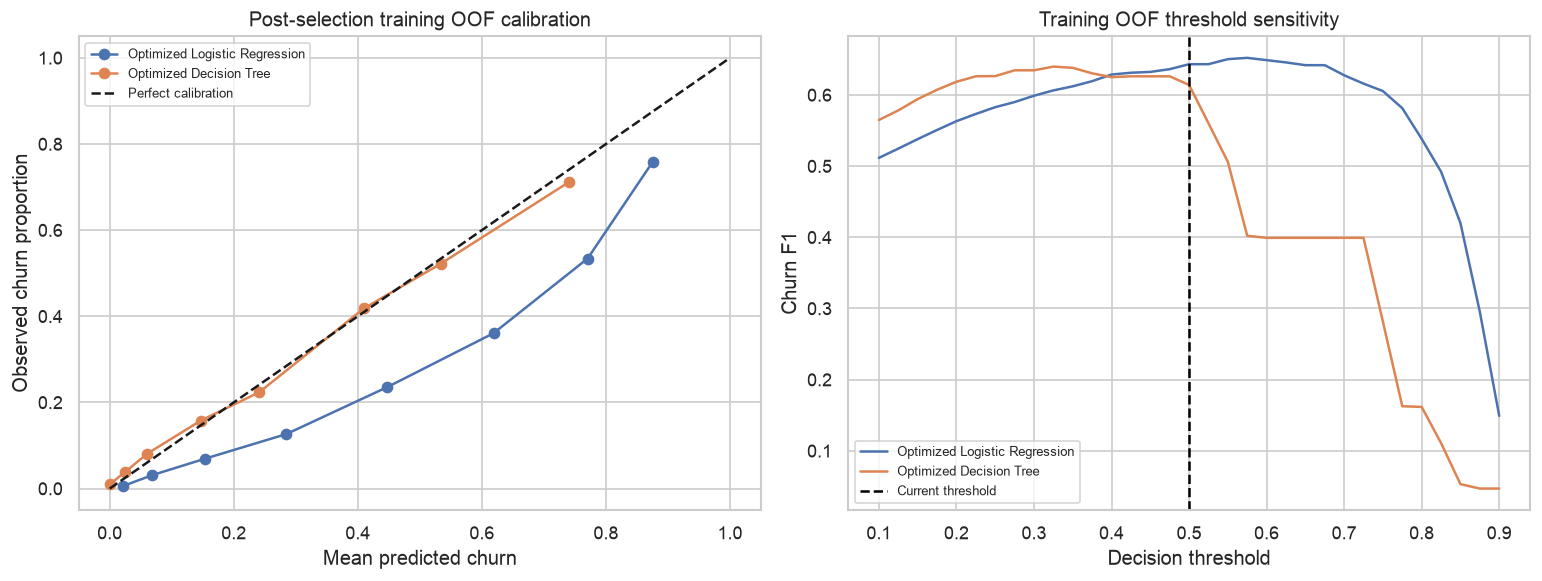


### What the probability and threshold diagnostics mean

Optimized LR's mean out-of-fold predicted churn is **40.5%**, versus an observed **26.5%**. The optimized tree's mean is **26.5%**. The reliability plot checks more than this overall average: a matching mean alone does not establish calibration across risk groups. LR's upward overall shift is consistent with the changed class-weighting objective; it should not be interpreted as evidence that 40% of customers will actually churn.

The threshold table shows that changing the cutoff can materially alter recall, precision and contact volume without retraining the model. These are pooled OOF metrics, which need not equal the unweighted mean of fold metrics in the search table. The curves are post-selection training diagnostics, so an apparent best cutoff needs separate validation. We retain each model's original default decision rule for the reported test comparison and exported pipeline. Better F1 is not the same as better probability calibration.


In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

oof_probabilities = {}
threshold_rows, calibration_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["Optimized Logistic Regression", "Optimized Decision Tree"]:
    model = models[name]
    oof = cross_val_predict(model, X_train, y_train, cv=CV,
                           method="predict_proba", n_jobs=1)[:, list(model.classes_).index(1)]
    oof_probabilities[name] = oof
    calibration_rows.append({"Model": name, "OOF Brier loss": brier_score_loss(y_train, oof),
                             "Mean predicted churn": oof.mean(), "Observed churn": y_train.mean()})
    observed, predicted = calibration_curve(y_train, oof, n_bins=8, strategy="quantile")
    axes[0].plot(predicted, observed, "o-", label=name)
    for threshold in [.30, .40, .50, .60, .70]:
        pred = (oof >= threshold).astype(int)
        threshold_rows.append({"Model": name, "Threshold": threshold,
            "Precision": precision_score(y_train, pred, zero_division=0),
            "Recall": recall_score(y_train, pred, zero_division=0),
            "F1": f1_score(y_train, pred, zero_division=0), "Flagged share": pred.mean()})
    thresholds = np.linspace(.1, .9, 33)
    axes[1].plot(thresholds, [f1_score(y_train, oof >= t, zero_division=0) for t in thresholds], label=name)
display(pd.DataFrame(calibration_rows).set_index("Model").round(4))
print(f"Constant training-prevalence Brier reference: {brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.4f}")
display(pd.DataFrame(threshold_rows).set_index(["Model", "Threshold"]).round(4))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[0].set(xlabel="Mean predicted churn", ylabel="Observed churn proportion", title="Post-selection training OOF calibration")
axes[1].axvline(.5, color="black", linestyle="--", label="Current threshold")
axes[1].set(xlabel="Decision threshold", ylabel="Churn F1", title="Training OOF threshold sensitivity")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Class weighting changes the fitted objective: balanced-LR probabilities should not automatically "
      "be interpreted as calibrated population churn risks. Brier loss reflects calibration and discrimination.")


from IPython.display import Markdown
calibration_table = pd.DataFrame(calibration_rows).set_index("Model")
lr_mean = calibration_table.loc["Optimized Logistic Regression", "Mean predicted churn"]
tree_mean = calibration_table.loc["Optimized Decision Tree", "Mean predicted churn"]
threshold_table = pd.DataFrame(threshold_rows)
display(Markdown(f"""
### What the probability and threshold diagnostics mean

Optimized LR's mean out-of-fold predicted churn is **{lr_mean:.1%}**, versus an observed **{y_train.mean():.1%}**. The optimized tree's mean is **{tree_mean:.1%}**. The reliability plot checks more than this overall average: a matching mean alone does not establish calibration across risk groups. LR's upward overall shift is consistent with the changed class-weighting objective; it should not be interpreted as evidence that 40% of customers will actually churn.

The threshold table shows that changing the cutoff can materially alter recall, precision and contact volume without retraining the model. These are pooled OOF metrics, which need not equal the unweighted mean of fold metrics in the search table. The curves are post-selection training diagnostics, so an apparent best cutoff needs separate validation. We retain each model's original default decision rule for the reported test comparison and exported pipeline. Better F1 is not the same as better probability calibration.
"""))


## 7. Model interpretation

Interpretation should explain the fitted models, distinguish marginal associations from conditional effects, and expose limits. We inspect LR coefficients and contrasts, tree rules and impurity importance, and permutation importance of original input fields.

**Logistic Regression:** numeric coefficients are changes in log-odds per training standard deviation. Exponentiating gives a model-implied odds multiplier, not a probability multiplier. For categoricals, all one-hot levels are retained with regularization; compare two levels using the difference between their coefficients, rather than interpreting a coefficient as an effect against an omitted reference category.

**Correlated predictors:** tenure and Total Charges are strongly related in EDA. A negative marginal churn correlation can coexist with a positive conditional LR coefficient. Holding tenure and all other features fixed asks a different question from comparing customers overall. This is not proof that increasing charges causes churn.

**Decision Tree:** split rules describe the fitted decision regions. Impurity importance is training-based, can be biased toward high-cardinality fields, and can distribute credit unpredictably among correlated features. Numeric split thresholds use standardized units. The original-field permutation analysis below provides a complementary view.


Largest absolute encoded coefficients; do not compare numeric and categorical magnitudes directly:
These conditional, regularized associations have no causal interpretation or coefficient uncertainty intervals.
Fitted tree depth: 5 | leaves: 25
Optimized Logistic Regression | diagnostic validation F1: 0.6345
Optimized Decision Tree | diagnostic validation F1: 0.5878
A raw column is shuffled before pipeline encoding, so all its one-hot levels are assessed together. Error bars show permutation-repeat SD, not confidence intervals. Correlated inputs can substitute for one another; shuffling can create unrealistic combinations. These are refitted diagnostic models.


,Coefficient
numeric__Tenure Months,-0.9949
categorical__Dependents_Yes,-0.7751
categorical__Dependents_No,0.7658
categorical__Contract_Month-to-month,0.6834
categorical__Contract_Two year,-0.6074
categorical__Zip Code_95567,0.3535
categorical__Internet Service_Fiber optic,0.3512
categorical__Zip Code_92382,0.3139
categorical__Internet Service_DSL,-0.2882
categorical__Zip Code_91773,0.2852


,Training scale (one SD),Log-odds per SD,Odds multiplier per SD
Input,,,
Tenure Months,24.5666,-0.9949,0.3698
Monthly Charges,30.1354,0.1136,1.1203
Total Charges,2277.6067,0.2777,1.3201


,Log-odds contrast,Model-implied odds ratio
Comparison holding other inputs fixed,,
Contract: Month-to-month versus Two year,1.2908,3.6357
Contract: Month-to-month versus One year,0.7687,2.1570
Dependents: Yes versus No,-1.5409,0.2142
Internet Service: Fiber optic versus DSL,0.6395,1.8954


,Impurity importance
categorical__Contract_Month-to-month,0.5014
numeric__Tenure Months,0.1286
categorical__Internet Service_Fiber optic,0.1155
categorical__Dependents_No,0.1079
numeric__Monthly Charges,0.0562
categorical__Payment Method_Electronic check,0.0203
numeric__Total Charges,0.0185
categorical__Online Security_No,0.0152
categorical__Tech Support_No,0.0150
categorical__Online Backup_No,0.0077


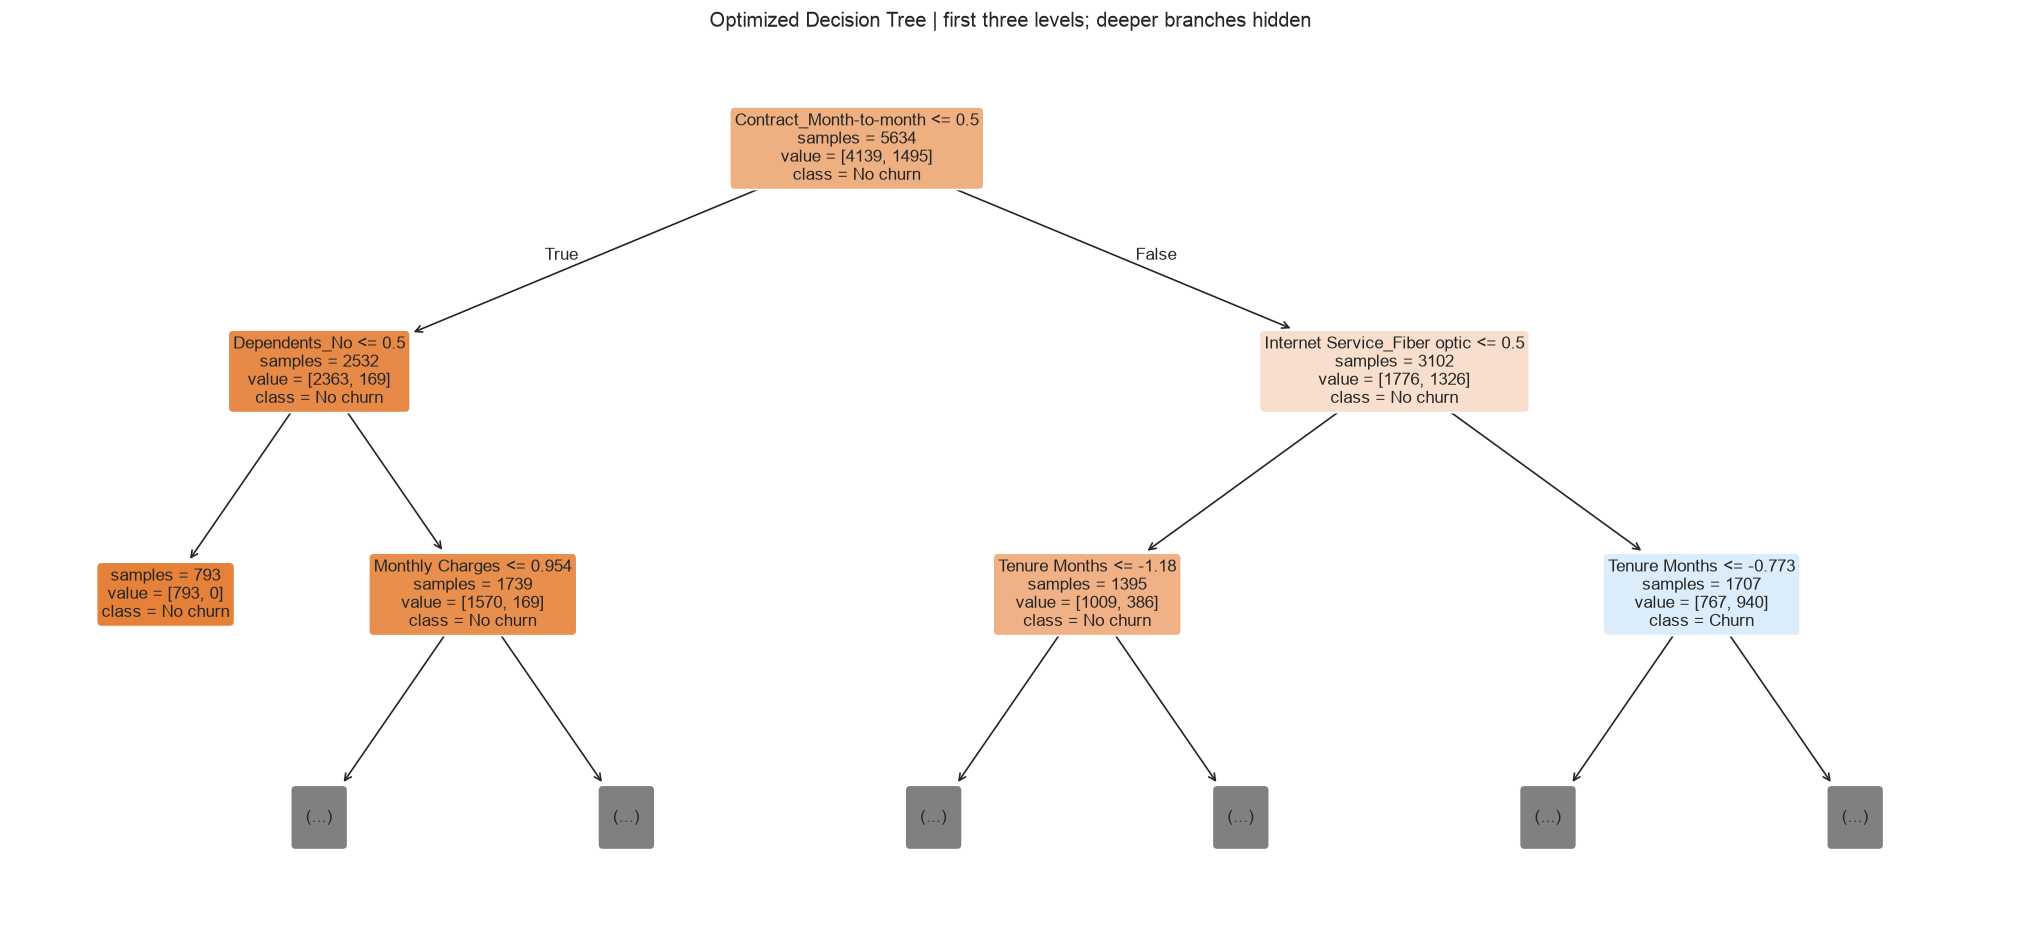

,Mean F1 decrease,Permutation SD
Tenure Months,0.1263,0.0105
Dependents,0.0443,0.0130
Contract,0.0314,0.0127
Tech Support,0.0076,0.0044
Streaming Movies,0.0067,0.0041
Monthly Charges,0.0059,0.0048
Partner,0.0055,0.0031
Phone Service,0.0044,0.0017
Device Protection,0.0037,0.0020
Payment Method,0.0032,0.0037


,Mean F1 decrease,Permutation SD
Contract,0.1831,0.0258
Online Security,0.1474,0.0241
Internet Service,0.1001,0.0150
Dependents,0.0788,0.0096
Total Charges,0.0269,0.0081
Tech Support,0.0000,0.0000
Monthly Charges,0.0000,0.0000
Payment Method,0.0000,0.0000
Paperless Billing,0.0000,0.0000
Streaming Movies,0.0000,0.0000


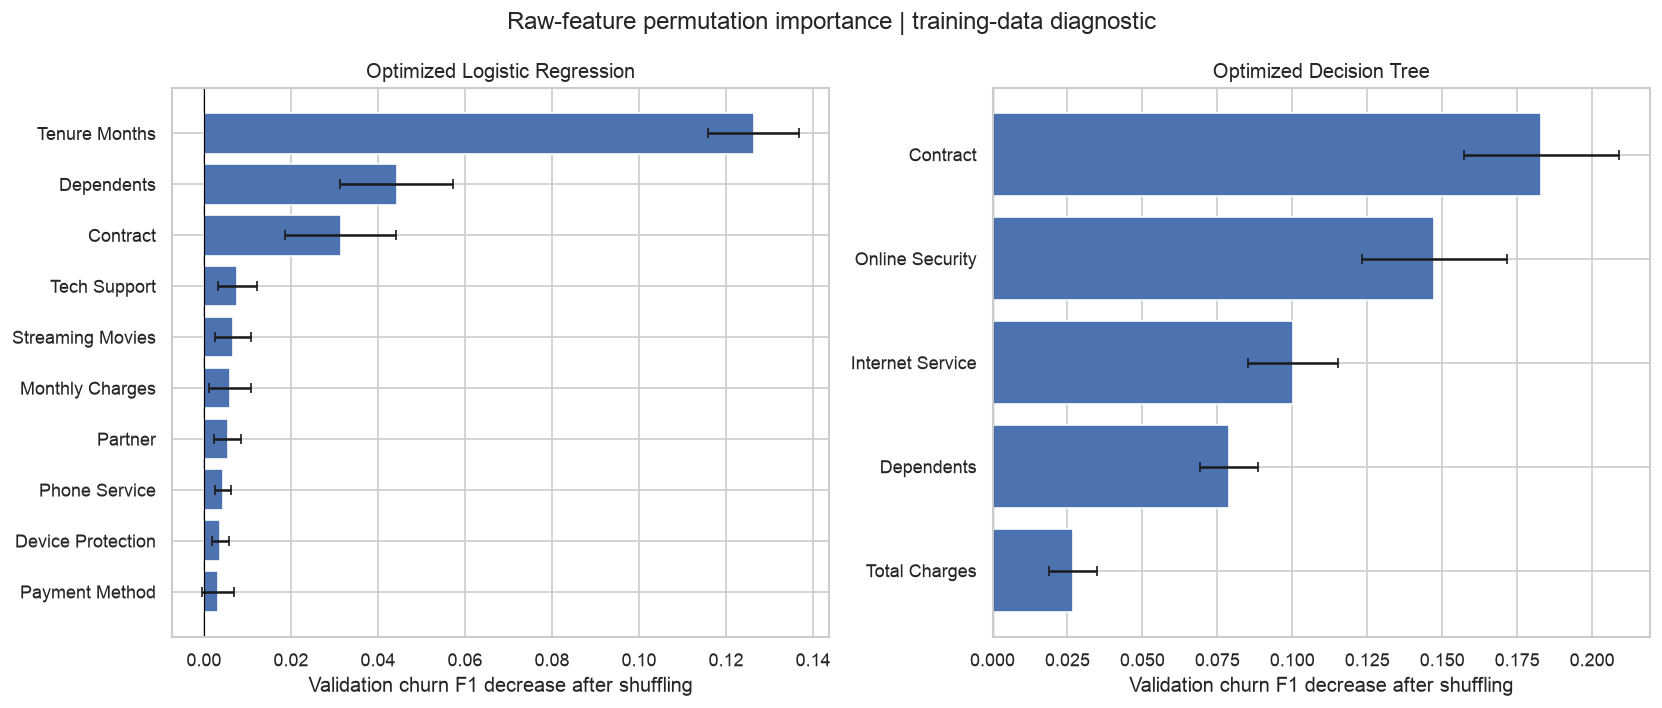

In [12]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance

linear_pipeline = models["Optimized Logistic Regression"]
linear_features = linear_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(linear_pipeline.named_steps["model"].coef_[0],
                         index=linear_features, name="Coefficient")
print("Largest absolute encoded coefficients; do not compare numeric and categorical magnitudes directly:")
display(coefficients.loc[coefficients.abs().sort_values(ascending=False).head(15).index].to_frame().round(4))
scaler = linear_pipeline.named_steps["preprocessor"].named_transformers_["numeric"].named_steps["scaler"]
numeric_effects = pd.DataFrame({"Input": numeric_columns,
    "Training scale (one SD)": scaler.scale_,
    "Log-odds per SD": [coefficients[f"numeric__{c}"] for c in numeric_columns]})
numeric_effects["Odds multiplier per SD"] = np.exp(numeric_effects["Log-odds per SD"])
display(numeric_effects.set_index("Input").round(4))

contrast_rows = []
for field, a, b in [("Contract", "Month-to-month", "Two year"),
                     ("Contract", "Month-to-month", "One year"),
                     ("Dependents", "Yes", "No"),
                     ("Internet Service", "Fiber optic", "DSL")]:
    difference = coefficients[f"categorical__{field}_{a}"] - coefficients[f"categorical__{field}_{b}"]
    contrast_rows.append({"Comparison holding other inputs fixed": f"{field}: {a} versus {b}",
                          "Log-odds contrast": difference, "Model-implied odds ratio": np.exp(difference)})
display(pd.DataFrame(contrast_rows).set_index("Comparison holding other inputs fixed").round(4))
print("These conditional, regularized associations have no causal interpretation or coefficient uncertainty intervals.")

tree_pipeline = models["Optimized Decision Tree"]
tree_features = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(tree_pipeline.named_steps["model"].feature_importances_,
                       index=tree_features, name="Impurity importance").sort_values(ascending=False)
display(importance.head(15).to_frame().round(4))
print("Fitted tree depth:", tree_pipeline.named_steps["model"].get_depth(),
      "| leaves:", tree_pipeline.named_steps["model"].get_n_leaves())
tree_display_names = [name.replace("categorical__", "").replace("numeric__", "") for name in tree_features]
plt.figure(figsize=(17, 8))
plot_tree(tree_pipeline.named_steps["model"], feature_names=tree_display_names,
          class_names=["No churn", "Churn"], filled=True, max_depth=2,
          fontsize=10, rounded=True, impurity=False)
plt.title("Optimized Decision Tree | first three levels; deeper branches hidden")
plt.tight_layout()
plt.show()

# Interpret on a held-out portion of the original training data, not the reused test.
# Configurations were tuned on the full training set, so this is exploratory attribution.
interpret_fit_X, interpret_valid_X, interpret_fit_y, interpret_valid_y = train_test_split(
    X_train, y_train, test_size=.25, stratify=y_train, random_state=73)
permutation_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["Optimized Logistic Regression", "Optimized Decision Tree"]):
    interpret_model = clone(models[name]).fit(interpret_fit_X, interpret_fit_y)
    permutation = permutation_importance(interpret_model, interpret_valid_X, interpret_valid_y,
        scoring="f1", n_repeats=8, random_state=RANDOM_STATE, n_jobs=1)
    table = pd.DataFrame({"Mean F1 decrease": permutation.importances_mean,
                          "Permutation SD": permutation.importances_std}, index=X_train.columns)
    permutation_tables[name] = table.sort_values("Mean F1 decrease", ascending=False)
    print(name, "| diagnostic validation F1:", round(f1_score(interpret_valid_y, interpret_model.predict(interpret_valid_X)), 4))
    display(permutation_tables[name].round(4))
    top = permutation_tables[name].query("`Mean F1 decrease` > 0").head(10).sort_values("Mean F1 decrease")
    ax.barh(top.index, top["Mean F1 decrease"], xerr=top["Permutation SD"], capsize=3)
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(title=name, xlabel="Validation churn F1 decrease after shuffling")
fig.suptitle("Raw-feature permutation importance | training-data diagnostic")
plt.tight_layout()
plt.show()
print("A raw column is shuffled before pipeline encoding, so all its one-hot levels are assessed together. "
      "Error bars show permutation-repeat SD, not confidence intervals. Correlated inputs can substitute "
      "for one another; shuffling can create unrealistic combinations. These are refitted diagnostic models.")


In [13]:
from IPython.display import Markdown
top_lr = ", ".join(permutation_tables["Optimized Logistic Regression"].head(3).index)
top_tree = ", ".join(permutation_tables["Optimized Decision Tree"].head(3).index)
total_coef = coefficients["numeric__Total Charges"]
total_corr = corr.loc["Total Charges", "Churn"]
display(Markdown(f"""
### Interpretation findings

In the training-validation permutation diagnostic, the three largest raw-field F1 decreases are **{top_lr}** for optimized LR and **{top_tree}** for the optimized tree. Read the full tables, including negative and near-zero values: a small decrease means limited incremental reliance in this diagnostic, not that a feature has no business relevance. Rankings depend on the fitted sample and F1 scoring.

**Total Charges illustrates conditional versus marginal interpretation:** its training churn correlation is **{total_corr:.4f}**, while its optimized LR standardized coefficient is **{total_coef:.4f}**. The coefficient holds tenure and other encoded inputs fixed. Strong tenure/charges correlation and regularization complicate attribution; neither quantity estimates the effect of changing a customer's bill.

The coefficient contrasts, visible tree rules and permutation diagnostics explain different aspects of the models. Agreement strengthens a descriptive interpretation; disagreement calls for stability checks and consideration of correlated inputs. None identifies customers whose churn would be prevented by an offer.
"""))


zip_lr = permutation_tables["Optimized Logistic Regression"].loc["Zip Code", "Mean F1 decrease"]
zip_tree = permutation_tables["Optimized Decision Tree"].loc["Zip Code", "Mean F1 decrease"]
tenure_tree = permutation_tables["Optimized Decision Tree"].loc["Tenure Months", "Mean F1 decrease"]
display(Markdown(f"""
**ZIP Code and stability:** shuffling ZIP Code changes diagnostic F1 by **{zip_lr:.4f}** for LR and **{zip_tree:.4f}** for the tree. This provides little evidence of incremental reliance in this particular split; it motivates a training-only removal comparison, rather than proving geography is useless.

The full-training tree assigns tenure substantial impurity importance, while the refitted diagnostic tree's tenure permutation decrease is **{tenure_tree:.4f}**. These are different fits on different samples and different importance definitions. Alternative split rules and correlated predictors can change which inputs a tree uses. The difference is a warning against treating one fitted importance ranking as a stable scientific explanation; repeated-fold attribution is a useful next step.
"""))



### Interpretation findings

In the training-validation permutation diagnostic, the three largest raw-field F1 decreases are **Tenure Months, Dependents, Contract** for optimized LR and **Contract, Online Security, Internet Service** for the optimized tree. Read the full tables, including negative and near-zero values: a small decrease means limited incremental reliance in this diagnostic, not that a feature has no business relevance. Rankings depend on the fitted sample and F1 scoring.

**Total Charges illustrates conditional versus marginal interpretation:** its training churn correlation is **-0.1948**, while its optimized LR standardized coefficient is **0.2777**. The coefficient holds tenure and other encoded inputs fixed. Strong tenure/charges correlation and regularization complicate attribution; neither quantity estimates the effect of changing a customer's bill.

The coefficient contrasts, visible tree rules and permutation diagnostics explain different aspects of the models. Agreement strengthens a descriptive interpretation; disagreement calls for stability checks and consideration of correlated inputs. None identifies customers whose churn would be prevented by an offer.



**ZIP Code and stability:** shuffling ZIP Code changes diagnostic F1 by **0.0000** for LR and **0.0000** for the tree. This provides little evidence of incremental reliance in this particular split; it motivates a training-only removal comparison, rather than proving geography is useless.

The full-training tree assigns tenure substantial impurity importance, while the refitted diagnostic tree's tenure permutation decrease is **0.0000**. These are different fits on different samples and different importance definitions. Alternative split rules and correlated predictors can change which inputs a tree uses. The difference is a warning against treating one fitted importance ranking as a stable scientific explanation; repeated-fold attribution is a useful next step.


## 8. Discussion and conclusion

**Reproduction and report synchronization.** This notebook records the package versions actually used for its saved outputs. Tree splits can differ across package versions, even with a fixed random seed. Use this execution as the source for the report tables; do not mix its baseline-tree results with an older run. The original notebook is retained in the local revision backup.

**What the experiment supports.** The fixed comparison evaluates four required classifiers using common observations, preprocessing and metrics. Optimized Logistic Regression is selected by training CV churn F1. The evaluation tables show whether this is supported on the reused test and quantify the accompanying precision, recall and workload trade-offs. Optimization is judged against F1, rather than assumed to improve every metric. The optimized tree is a practical alternative if false-alert burden matters more.

**Why the results occur.** Balanced class weighting changes the LR training objective, increasing attention to churners. Stronger regularization limits coefficient magnitude in a feature space containing many ZIP indicators. Tree depth and minimum leaf constraints reduce the unrestricted tree's ability to memorize training observations. Because multiple settings change together, controlled ablations would be needed to isolate each contribution.

**How much confidence is justified?** The bootstrap describes variation among the observed test customers conditional on fixed models and class prevalence. It does not undo test reuse or account for training and model-selection uncertainty. Post-selection OOF and interpretation-holdout analyses are diagnostics. No claim of a statistically confirmed winner follows from these results. New independent customers, preferably from a later period, are the priority before further performance claims.

**Business meaning.** Churn prediction can prioritize review, but it does not establish that a retention offer changes behavior. The error-cost table exposes dependence on assumptions; it is not a financial forecast. High recall may exceed contact capacity, and unknown response rates prevent a return-on-investment claim. Ultimately compare a retention intervention with a control group, measuring incremental retention and net value.

| Limitation | Consequence | Evidence or next action |
| --- | --- | --- |
| Reused test and post-selection diagnostics | Reported performance may be optimistic | Freeze the workflow; validate on new/later customers; nested CV can support further development |
| No verified scoring date or future prediction horizon | Retrospective classification may not reproduce operational prediction | Define a horizon, such as next 30 days if appropriate; verify every feature exists at scoring time |
| California-only records and class imbalance | Performance and precision can change in other populations | Validate by region/time; track prevalence, precision-recall and data drift |
| ZIP Code has many categories | Local memorization, unseen categories and geographic proxies are concerns | Training-only feature ablation and geographic validation; review subgroup stability and privacy |
| Unknown error and campaign costs | F1 is a technical compromise rather than an economic optimum | Measure contact/offer costs, customer value, capacity and intervention effectiveness |
| Correlated inputs and observational labels | Coefficients and importance are unstable or noncausal | Repeat attribution across folds; avoid causal business claims |
| Uncalibrated probabilities, especially with weighting | A score need not equal an actual churn probability | Evaluate calibration on independent validation; calibrate and choose thresholds within training validation |

**Operational recommendation.** Carry the CV-selected optimized Logistic Regression into independent validation, alongside the optimized tree as a challenger. Keep the current decision rule for this experiment. Before a pilot, specify the scoring horizon, data contract, contact capacity, calibrated risk requirements, threshold policy and acceptance criteria. Assess relevant subgroup precision, recall and calibration with sample sizes, then document review procedures. Track input quality, drift, alert volume and delayed-label performance, with retraining triggers and rollback ownership.

**Lessons learned.** Perfect fitting accuracy can conceal overfitting. A smaller training/test gap alone does not identify the best classifier. Ranking, threshold decisions and probability calibration answer different questions. A model that finds more churners can create substantially more work. Reproducible validation and honest uncertainty matter more than a small score advantage.

**Conclusion.** This project produces an interpretable, reproducible churn-classification candidate and an evidence-based comparison. It supports further validation of optimized Logistic Regression under the F1 objective. It does not yet establish an independently validated, profitable or production-ready retention system.

## Submission checklist

- [x] Problem, target, predictors, schema and exclusions explained.
- [x] EDA, missing values, shared preprocessing and four required models included.
- [x] Training/test accuracy, per-class reports, confusion matrices and comparison discussion included.
- [x] Additional uncertainty, cost, calibration and interpretation diagnostics labeled with their limitations.
- [ ] Export and visually review `Group4.pdf`; synchronize its tables and findings with this notebook execution.
- [ ] Validate the fixed workflow independently before operational deployment.

## References

[1] Yeanzc. Telco customer churn: IBM dataset. Kaggle. https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset

[2] scikit-learn developers. Common pitfalls and recommended practices. https://scikit-learn.org/stable/common_pitfalls.html

[3] scikit-learn developers. LogisticRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

[4] scikit-learn developers. DecisionTreeClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

[5] scikit-learn developers. GridSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

[6] scikit-learn developers. Permutation feature importance. https://scikit-learn.org/stable/modules/permutation_importance.html

[7] scikit-learn developers. Probability calibration. https://scikit-learn.org/stable/modules/calibration.html


## 9. Export the model and use the local API

Export the CV-selected fitted pipeline, including preprocessing. This artifact uses the existing training fit; it is not refitted on test data. Run this cell again whenever the model or its inputs change. `models/churn_pipeline.joblib` is used by `api/server.py`; `models/example_request.json` contains a valid example request. The probability is a model estimate, not a guarantee of churn. This local API demonstrates inference and is not a production deployment.


In [14]:
import json
import platform
import joblib

export_dir = Path("models")
export_dir.mkdir(exist_ok=True)
selected_pipeline = models[recommended_name]
fields = []
for name in X_train.columns:
    field = {"name": name, "type": "number" if name in numeric_columns else "string"}
    if name not in numeric_columns:
        field["categories"] = sorted(X_train[name].dropna().astype(str).unique().tolist())
    fields.append(field)
example = json.loads(X_train.iloc[0].to_json())
artifact = {
    "artifact_version": 1,
    "model_name": recommended_name,
    "pipeline": selected_pipeline,
    "fields": fields,
    "example": example,
    "excluded_columns": excluded,
    "target": TARGET_COLUMN,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                 "joblib": joblib.__version__},
}
joblib.dump(artifact, export_dir / "churn_pipeline.joblib")
(export_dir / "schema.json").write_text(json.dumps(
    {k: v for k, v in artifact.items() if k != "pipeline"}, indent=2, ensure_ascii=False) + "\n")
(export_dir / "example_request.json").write_text(
    json.dumps({"customer": example}, indent=2, ensure_ascii=False) + "\n")
print("Exported:", artifact["model_name"])
print("Predictor count:", len(fields))
print("Start the API: python3 api/server.py")


Exported: Optimized Logistic Regression
Predictor count: 20
Start the API: python3 api/server.py
